# 14 — A mini continuous search: sliding windows, trigger clustering, FAR in years⁻¹

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Turns the per-window analysis into a search over continuous data (extension 9). On the two H1+L1 *test* chunks of notebook 09 (≈2.3 h of two-detector data) it slides the 1 s window with a 0.5 s step, evaluates the IMR bank in both detectors, forms the coincident statistic (Fisher combination of the single-detector p-values of notebook 13, arrival-time gate 15 ms), **clusters** the triggers (one trigger per ±1 s), builds the background by **time slides of the same data** (every shift of L1 by k·0.5 s, ≈6·10⁷ window pairs) and expresses the significance as a **false-alarm rate in years⁻¹**. It lists the loudest candidates and checks the recovery of 40 IMR signals injected in the same continuous data.

**What it does not do.** Chunks are ≥2000 s away from catalogued events, so no real event is expected: the candidates are what noise (glitches) produces. The two detectors are combined incoherently, there are no chi² vetoes and no data-quality flags, the p-value background is that of notebook 09 (other epochs), and the FAR is for this pipeline and these chunks, not an LVK false-alarm rate.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import imr_tools as it
import gwosc_tools as g
g.style()
CHK = g.load_json("coinc_chunks.json"); TEST_IDX = [2, 5]; DET = ("H1", "L1"); STEP = 512; GATE = 0.015
BKG = np.load(os.path.join(g.CACHE, "bkg13.npz")); BKG = {tuple(k.split("|")): BKG[k] for k in BKG.files}      # per-detector IMR background of nb 13
SB = {d: np.sort(BKG[("imr", d)]) for d in DET}
def pscore(d, x): return -np.log((len(SB[d]) - np.searchsorted(SB[d], x, side="left") + 1.0) / (len(SB[d]) + 1.0))
def sliding(v):
    n = (len(v) - g.NWIN) // STEP + 1
    return np.lib.stride_tricks.sliding_window_view(v, g.NWIN)[::STEP][:n]
RAW = {(k, d): np.load(os.path.join(g.CACHE, "raw", CHK[k]["files"][d])) for k in TEST_IDX for d in DET}
WH = {(k, d): g.whiten_chunk(RAW[(k, d)]) for k in TEST_IDX for d in DET}      # (v, f_psd, S)
print({k: len(v[0]) / g.FS for k, v in WH.items()}, "seconds of whitened data")

{(2, 'H1'): 4096.0, (2, 'L1'): 4096.0, (5, 'H1'): 4096.0, (5, 'L1'): 4096.0} seconds of whitened data


## 1. Per-window statistics on overlapping windows (clean data and, later, data with injections)

In [2]:
def stats(v, S1, bank):
    w = sliding(v[g.TRIM * g.FS: len(v) - g.TRIM * g.FS]); o = bank.scan(g.to_bins(w))
    return o["rho2"], o["tau"], o["f0"]
BANKS = {(k, d): it.IMRBank(g.psd_1hz(WH[(k, d)][1], WH[(k, d)][2])) for k in TEST_IDX for d in DET}
t0_ = time.time()
ST = {key: stats(WH[key][0], None, BANKS[key]) for key in WH}
print("scan: %.0f s;" % (time.time() - t0_), {k: len(v[0]) for k, v in ST.items()}, "windows")

scan: 15 s; {(2, 'H1'): 8111, (2, 'L1'): 8111, (5, 'H1'): 8111, (5, 'L1'): 8111} windows


## 2. Coincident statistic, clustering, and time slides

In [3]:
def coinc(sH, sL, shift=0):
    # statistic of the pairs (H window i, L window i + shift): Fisher of p-values, zero if the arrival times (window start + tau) differ by > GATE
    n = len(sH[0]); idx = (np.arange(n) + shift) % n
    S = pscore("H1", sH[0]) + pscore("L1", sL[0][idx])
    # paired windows are aligned (same start in the common frame): the arrival times differ by the difference of the in-window times tau
    return np.where(np.abs(sH[1] - sL[1][idx]) <= GATE, S, 0.0)
def cluster(S, floor):
    # one trigger per +-1 s (2 windows): keep local maxima above the floor
    n = len(S); pk = (S > floor)
    for sft in (1, 2):
        pk &= S >= np.roll(S, sft); pk &= S >= np.roll(S, -sft)
    return np.where(pk)[0]
ZL = {k: coinc(ST[(k, "H1")], ST[(k, "L1")]) for k in TEST_IDX}
FLOOR = 6.0; NS = {k: len(ZL[k]) for k in TEST_IDX}
t0_ = time.time(); BGS = []; BGK = {k: [] for k in TEST_IDX}; TSK = {k: 0.0 for k in TEST_IDX}; Tslide = 0.0
for k in TEST_IDX:
    for sh in range(8, NS[k] - 8):                                    # shifts > 4 s: the two noises are not the same noise
        S = coinc(ST[(k, "H1")], ST[(k, "L1")], sh); b = S[cluster(S, FLOOR)]; BGS.append(b); BGK[k].append(b); Tslide += NS[k] * STEP / g.FS; TSK[k] += NS[k] * STEP / g.FS
BGS = np.sort(np.concatenate(BGS))[::-1]; YEAR = 365.25 * 86400
Tzero = sum(NS[k] * STEP / g.FS for k in TEST_IDX)
print("slides: %.0f s; background time %.2e s = %.1f yr; clustered background triggers above S=%g: %d" % (time.time() - t0_, Tslide, Tslide / YEAR, FLOOR, len(BGS)))
def far_per_year(S): return (np.searchsorted(-BGS, -S, side="right")) / (Tslide / YEAR)       # background triggers with S' >= S per year

slides: 33 s; background time 6.57e+07 s = 2.1 yr; clustered background triggers above S=6: 510689


In [4]:
zl = [(k, i, ZL[k][i]) for k in TEST_IDX for i in cluster(ZL[k], FLOOR)]
cand = pd.DataFrame(zl, columns=["chunk", "win", "S"]).sort_values("S", ascending=False).reset_index(drop=True)
cand["gps"] = [CHK[k]["gps_start"] + g.TRIM + i * STEP / g.FS for k, i in zip(cand.chunk, cand.win)]
cand["FAR_per_yr"] = [far_per_year(s) for s in cand.S]
cand["n_exp_in_data"] = cand.FAR_per_yr * Tzero / YEAR            # expected number of noise triggers at least this loud in the searched data
rho = lambda k, d, i: float(np.sqrt(ST[(k, d)][0][i]))
cand["rho_H"] = [rho(k, "H1", i) for k, i in zip(cand.chunk, cand.win)]; cand["rho_L"] = [rho(k, "L1", i) for k, i in zip(cand.chunk, cand.win)]
cand["M_H"] = [ST[(k, "H1")][2][i] for k, i in zip(cand.chunk, cand.win)]
print("searched two-detector time: %.2f h;  zero-lag clustered triggers above S=%g: %d  (background expectation %.1f)" % (Tzero / 3600, FLOOR, len(cand), len(BGS) * Tzero / Tslide))
cand.head(12).round(3)

searched two-detector time: 2.25 h;  zero-lag clustered triggers above S=6: 62  (background expectation 63.1)


,chunk,win,S,gps,FAR_per_yr,n_exp_in_data,rho_H,rho_L,M_H
0,2,6927,9.776,1.129521e+09,6662.041,1.712,67.886,4.891,50.0
1,2,6887,9.708,1.129521e+09,7186.410,1.847,296.181,4.654,50.0
2,2,6672,9.579,1.129520e+09,8238.514,2.117,11.111,5.333,60.0
3,2,6934,9.376,1.129521e+09,10275.913,2.641,49.664,4.751,50.0
4,5,1811,8.950,1.137243e+09,16244.401,4.175,4.468,7.339,30.0
5,5,1755,8.771,1.137243e+09,19737.154,5.073,4.655,6.970,30.0
6,2,7700,8.740,1.129521e+09,20403.310,5.244,5.960,5.386,50.0
7,2,7209,8.447,1.129521e+09,27923.279,7.177,8.782,4.968,42.0
8,2,7440,8.303,1.129521e+09,32620.496,8.384,6.489,5.082,85.0
9,2,6835,8.129,1.129520e+09,39349.345,10.114,33.174,4.433,50.0


In [5]:
# zero-lag against slides of the SAME chunk: independent noises -> ratio 1; time-correlated non-Gaussianity -> excess
rows = []
for k in TEST_IDX:
    bk = np.concatenate(BGK[k]); zk = ZL[k][cluster(ZL[k], FLOOR)]
    for thr in (6, 7, 8, 9):
        exp = (bk >= thr).sum() * (NS[k] * STEP / g.FS) / TSK[k]; rows.append(dict(chunk=k, S_above=thr, zero_lag=int((zk >= thr).sum()), expected_from_slides=exp))
ZC = pd.DataFrame(rows); ZC["ratio"] = ZC.zero_lag / ZC.expected_from_slides; ZC.round(2)

,chunk,S_above,zero_lag,expected_from_slides,ratio
0,2,6,54,54.17,1.00
1,2,7,25,24.88,1.00
2,2,8,9,9.21,0.98
3,2,9,4,3.04,1.32
4,5,6,8,8.92,0.90
5,5,7,4,4.79,0.83
6,5,8,2,2.40,0.83
7,5,9,0,0.93,0.00


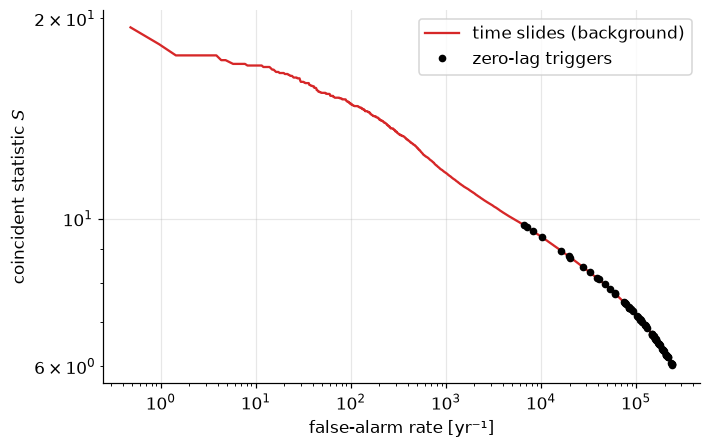

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.4))
xs = np.sort(BGS); far = (len(xs) - np.arange(len(xs))) / (Tslide / YEAR)
ax.loglog(np.maximum(far, 1e-12), xs, color=g.COLORS["bayes"], label="time slides (background)")
ax.loglog(np.maximum(cand.n_exp_in_data.values * YEAR / Tzero, 1e-12), cand.S.values, "ko", ms=4, label="zero-lag triggers")
ax.invert_xaxis() if False else None
ax.set_xlabel("false-alarm rate [yr⁻¹]"); ax.set_ylabel(r"coincident statistic $S$"); ax.legend()
g.savefig(fig, "fig14_search_ifar"); plt.show()

## 3. Recovery of injected signals in the continuous data

In [7]:
rng = np.random.default_rng(14); NINJ = 40; rows = []
def inject_continuous(k, rho_net, t_gps_off):
    out = {}
    p = g.draw_params("imr_test", rng, 1); alpha = rng.uniform(0.45, 1.12)
    for d, rho in (("H1", rho_net * np.cos(alpha)), ("L1", rho_net * np.sin(alpha))):
        v = WH[(k, d)][0].copy(); i0 = int(t_gps_off * g.FS)
        w = v[i0:i0 + g.NWIN][None]; S1 = g.psd_1hz(WH[(k, d)][1], WH[(k, d)][2])[None]
        ser, _, _ = g.inject(w, "imr_test", rho, rng, S1, params=p); v[i0:i0 + g.NWIN] = ser[0]; out[d] = v
    return out
found = []
for snr in (8, 10, 12, 15):
    for j in range(NINJ // 4):
        k = TEST_IDX[j % 2]; off = float(rng.uniform(100, 3900)); vv = inject_continuous(k, snr, off)
        sH = stats(vv["H1"], None, BANKS[(k, "H1")]); sL = stats(vv["L1"], None, BANKS[(k, "L1")])
        S = coinc(sH, sL); i_inj = int((off - g.TRIM) * g.FS / STEP)
        lo, hi = max(i_inj - 2, 0), i_inj + 3; found.append(dict(rho_net=snr, S=float(S[lo:hi].max()), FAR_per_yr=far_per_year(float(S[lo:hi].max()))))
F = pd.DataFrame(found); F["detected_FAR<1/yr"] = F.FAR_per_yr < 1; F["detected_FAR<1e3/yr"] = F.FAR_per_yr < 1e3
F.groupby("rho_net")[["detected_FAR<1e3/yr", "detected_FAR<1/yr"]].mean().round(2)

,detected_FAR<1e3/yr,detected_FAR<1/yr
rho_net,,
8,0.1,0.0
10,0.4,0.0
12,0.7,0.0
15,1.0,0.0


In [8]:
g.save_json(dict(step_s=STEP / g.FS, searched_hours=Tzero / 3600, background_years=Tslide / YEAR, floor=FLOOR, n_zero_lag=len(cand), n_bkg_expected=len(BGS) * Tzero / Tslide,
                 zero_lag_vs_slides=ZC.to_dict("records"), candidates=cand.head(20).to_dict("records"), recovery=F.groupby("rho_net")[["detected_FAR<1e3/yr", "detected_FAR<1/yr"]].mean().reset_index().to_dict("records")), "14_summary.json"); print("saved")

saved


## Output and next step

`results/14_summary.json`, `figures/fig14_search_ifar`. The IFAR plot compares the zero-lag triggers with the time-slide background: a flat agreement means the data contain no foreground at these significances, as expected for chunks far from events. Next: ablation of why the CNN beats the matched-filter bank (extension 33).